# Phase 1: Setup and raw data inspection (MATR fast-charge dataset)

Battery SOH estimation. Verifies the environment and GPU, then inspects the three raw HDF5 files read-only. Nothing is cleaned, stitched, split, featurised or trained on dataset data.

## 0. Configuration
Imports, constants and paths. Missing packages stop the run with a uv hint.

In [1]:
import sys, os, time, json, math, copy, hashlib, platform, shutil, subprocess, random, re
import importlib.util
import importlib.metadata as md
from pathlib import Path
from datetime import datetime
from collections import Counter

# Stop early (with a uv hint) if a required package is missing. Nothing is installed here.
REQUIRED = {"torch": "torch", "numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "h5py": "h5py",
            "scikit-learn": "sklearn", "matplotlib": "matplotlib", "pyarrow": "pyarrow",
            "tqdm": "tqdm", "psutil": "psutil"}
_missing = [dist for dist, mod in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    _msg = ("Missing packages: " + ", ".join(_missing) + ".\n"
            "Install them with uv from the project root, e.g.:  uv add " + " ".join(_missing) + "\n"
            "(torch must come from the project's CUDA wheel index.) Then restart the kernel and run again.")
    print(_msg)
    raise RuntimeError(_msg)

import numpy as np
import pandas as pd
import h5py
import psutil
import matplotlib.pyplot as plt
import torch
from torch import nn
from tqdm import tqdm

# ---- configuration ----
SEED = 42
COMPUTE_SHA256 = True
NOMINAL_AH = 1.1
EOL_FRACTION = 0.8
EOL_AH = round(NOMINAL_AH * EOL_FRACTION, 6)          # 0.88 Ah

BATCH_PREFIX = {"2017-05-12": 1, "2017-06-30": 2, "2018-04-12": 3}   # file-name date prefix -> batch
EXPECTED_CELLS = {1: 46, 2: 48, 3: 46}

# ---- paths ----
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "data/raw/MATR").is_dir(), f"Raw data folder not found: {ROOT / 'data/raw/MATR'}"
RAW = ROOT / "data/raw/MATR"
OUT = ROOT / "outputs/phase1"
FIG = OUT / "figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# ---- seeding ----
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("ROOT:", ROOT)
print("RAW :", RAW)
print("OUT :", OUT)

ROOT: c:\workstation\3RD YEAR\Battery-Health-Estimation
RAW : c:\workstation\3RD YEAR\Battery-Health-Estimation\data\raw\MATR
OUT : c:\workstation\3RD YEAR\Battery-Health-Estimation\outputs\phase1


## Shared helpers
Check collector, error recorder, section timer and JSON conversion.

In [2]:
T0 = time.time()
CHECKS, ERRORS, ANOMALIES = [], [], []
SECTION_TIMES = {}
_cur = {"name": "setup", "t0": time.time()}


def A(x):
    # plain-ASCII text for everything printed or stored in the report
    return str(x).encode("ascii", "replace").decode("ascii")


def section(name):
    # close the timer of the previous section and start a new one
    now = time.time()
    SECTION_TIMES[_cur["name"]] = SECTION_TIMES.get(_cur["name"], 0.0) + (now - _cur["t0"])
    _cur["name"], _cur["t0"] = name, now


def check(name, passed, detail="", level="FAIL"):
    # level = status used when the check does not pass: FAIL (hard requirement) or WARN (expectation)
    status = "PASS" if bool(passed) else level
    CHECKS.append({"section": _cur["name"], "name": A(name), "status": status, "detail": A(detail)})
    print(f"[{status}] {A(name)}" + (f" | {A(detail)}" if detail != "" else ""))
    return status == "PASS"


def record_error(where, exc):
    txt = A(f"{where}: {type(exc).__name__}: {exc}")
    ERRORS.append(txt)
    print("[ERROR] " + txt)


def note(text):
    ANOMALIES.append(A(text))
    print("[NOTE] " + A(text))


def to_py(o):
    # numpy / pandas / pathlib values -> plain Python (NaN and inf become null)
    if isinstance(o, dict):
        return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, set)):
        return [to_py(v) for v in o]
    if isinstance(o, np.ndarray):
        return to_py(o.tolist())
    if isinstance(o, (bool, np.bool_)):
        return bool(o)
    if isinstance(o, (int, np.integer)):
        return int(o)
    if isinstance(o, (float, np.floating)):
        v = float(o)
        return None if (math.isnan(v) or math.isinf(v)) else v
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (pd.Timestamp, datetime)):
        return o.isoformat()
    if o is None or isinstance(o, str):
        return o
    return str(o)


def dump_json(obj, path):
    with open(path, "w", encoding="ascii") as fh:
        json.dump(to_py(obj), fh, indent=2, ensure_ascii=True)

## 1. Environment audit
Python, OS, hardware, package versions, forbidden helper packages, and the package lock list.

In [3]:
section("1 Environment audit")
CORE_PKGS = ["torch", "numpy", "pandas", "scipy", "h5py", "scikit-learn", "matplotlib", "pyarrow", "psutil"]


def pkg_version(name):
    try:
        return md.version(name)
    except md.PackageNotFoundError:
        return None


def is_inside(path, parent):
    p = os.path.normcase(os.path.abspath(str(path)))
    q = os.path.normcase(os.path.abspath(str(parent)))
    return p == q or p.startswith(q + os.sep)


def installed_packages():
    seen = {}
    for d in md.distributions():
        try:
            name = d.metadata["Name"]
            if name:
                seen[name.lower().replace("_", "-")] = (name, d.version)
        except Exception as e:
            record_error("installed_packages", e)
    return [f"{n}=={v}" for _, (n, v) in sorted(seen.items())]


VENV = ROOT / ".venv"
vm = psutil.virtual_memory()
du = shutil.disk_usage(ROOT)
ENV = {
    "python_version": platform.python_version(),
    "python_executable": sys.executable,
    "venv_expected": str(VENV),
    "os": platform.platform(),
    "machine": platform.machine(),
    "cpu_count": os.cpu_count(),
    "ram_total_gb": round(vm.total / 1024**3, 2),
    "ram_available_gb": round(vm.available / 1024**3, 2),
    "disk_free_gb": round(du.free / 1024**3, 2),
    "disk_total_gb": round(du.total / 1024**3, 2),
    "packages": {p: pkg_version(p) for p in CORE_PKGS + ["tqdm"]},
}

check("Python version is 3.13", sys.version_info[:2] == (3, 13), ENV["python_version"])
check("Interpreter lies inside ROOT/.venv",
      is_inside(sys.executable, VENV) or is_inside(sys.prefix, VENV), sys.executable, level="WARN")
for p, v in ENV["packages"].items():
    check(f"package installed: {p}", v is not None, v)
for p in ("torchvision", "torchaudio"):
    v = pkg_version(p)
    check(f"{p} not installed (no pretrained-weight helpers)", v is None, "absent" if v is None else f"found {v}")

lock = installed_packages()
(OUT / "requirements_lock.txt").write_text("\n".join(lock) + "\n", encoding="ascii", errors="replace")
ENV["n_installed_distributions"] = len(lock)

print()
for k in ("python_version", "python_executable", "os", "machine", "cpu_count", "ram_total_gb",
          "ram_available_gb", "disk_free_gb", "disk_total_gb"):
    print(f"{k:20s}: {A(ENV[k])}")
for p, v in ENV["packages"].items():
    print(f"{p:20s}: {v}")
print(f"requirements_lock.txt: {len(lock)} distributions written")

[PASS] Python version is 3.13 | 3.13.13
[PASS] Interpreter lies inside ROOT/.venv | c:\workstation\3RD YEAR\Battery-Health-Estimation\.venv\Scripts\python.exe
[PASS] package installed: torch | 2.14.1+cu130
[PASS] package installed: numpy | 2.5.4
[PASS] package installed: pandas | 3.1.0
[PASS] package installed: scipy | 1.18.1
[PASS] package installed: h5py | 3.16.0
[PASS] package installed: scikit-learn | 1.9.1
[PASS] package installed: matplotlib | 3.11.2
[PASS] package installed: pyarrow | 26.0.0
[PASS] package installed: psutil | 7.2.2
[PASS] package installed: tqdm | 4.70.1
[PASS] torchvision not installed (no pretrained-weight helpers) | absent
[PASS] torchaudio not installed (no pretrained-weight helpers) | absent

python_version      : 3.13.13
python_executable   : c:\workstation\3RD YEAR\Battery-Health-Estimation\.venv\Scripts\python.exe
os                  : Windows-11-10.0.26300-SP0
machine             : AMD64
cpu_count           : 12
ram_total_gb        : 15.71
ram_available

## 2. GPU verification
nvidia-smi, torch CUDA facts, and smoke tests on synthetic data only.

In [4]:
section("2 GPU verification")


def run_nvidia_smi():
    base = "name,driver_version,memory.total,memory.used"
    err = ""
    for q in (base + ",compute_cap", base):               # compute_cap is not supported by every driver
        try:
            r = subprocess.run(["nvidia-smi", f"--query-gpu={q}", "--format=csv,noheader"],
                               capture_output=True, text=True, timeout=30)
        except Exception as e:
            return {"ok": False, "error": f"{type(e).__name__}: {e}"}
        if r.returncode == 0:
            fields = q.split(",")
            rows = [dict(zip(fields, [x.strip() for x in line.split(",")])) for line in r.stdout.strip().splitlines()]
            return {"ok": True, "query": q, "gpus": rows}
        err = (r.stderr or r.stdout).strip()
    return {"ok": False, "error": err}


def arch_covered(cap, arch_list):
    # exact sm_XY, an older cubin of the same major version, or a PTX arch that is not newer
    code_ = cap[0] * 10 + cap[1]
    exact = f"sm_{code_}" in arch_list
    cubin = ptx = False
    for a in arch_list:
        m = re.match(r"(sm|compute)_(\d+)", a)
        if not m:
            continue
        kind, num = m.group(1), int(m.group(2))
        if kind == "sm" and num // 10 == cap[0] and num <= code_:
            cubin = True
        if kind == "compute" and num <= code_:
            ptx = True
    return (exact or cubin or ptx), {"exact": exact, "same_major_cubin": cubin, "ptx_fallback": ptx}


NVSMI = run_nvidia_smi()
if NVSMI["ok"]:
    for g in NVSMI["gpus"]:
        print("nvidia-smi:", A(g))
else:
    print("nvidia-smi unavailable:", A(NVSMI["error"]))

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True      # makes the repeatability test meaningful
torch.backends.cudnn.allow_tf32 = False        # exact fp32 for the CPU/GPU parity test

CUDA_OK = torch.cuda.is_available()
GPU = {
    "torch_version": torch.__version__,
    "torch_cuda_version": torch.version.cuda,
    "cuda_available": CUDA_OK,
    "cudnn_version": torch.backends.cudnn.version(),
    "cudnn_benchmark": torch.backends.cudnn.benchmark,
}
check("CUDA available to torch", CUDA_OK, f"torch {torch.__version__}, cuda {torch.version.cuda}")
if CUDA_OK:
    props = torch.cuda.get_device_properties(0)
    cap = torch.cuda.get_device_capability(0)
    GPU.update({
        "device_name": props.name, "capability": list(cap),
        "total_vram_gb": round(props.total_memory / 1024**3, 2),
        "arch_list": torch.cuda.get_arch_list(),
        "bf16_supported": bool(torch.cuda.is_bf16_supported()),
    })
    ok, how = arch_covered(cap, GPU["arch_list"])
    GPU["arch_coverage"] = how
    check("torch arch list covers device capability", ok, f"sm_{cap[0]}{cap[1]} in {GPU['arch_list']} -> {how}")
    check("compute capability is 8.6 (expected for RTX 3050)", cap == (8, 6), f"{cap[0]}.{cap[1]}", level="WARN")
    check("bf16 supported", GPU["bf16_supported"], "", level="WARN")
for k, v in GPU.items():
    print(f"{k:18s}: {A(v)}")

nvidia-smi: {'name': 'NVIDIA GeForce RTX 3050 6GB Laptop GPU', 'driver_version': '595.71', 'memory.total': '6144 MiB', 'memory.used': '0 MiB', 'compute_cap': '8.6'}
[PASS] CUDA available to torch | torch 2.14.1+cu130, cuda 13.0
[PASS] torch arch list covers device capability | sm_86 in ['sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120'] -> {'exact': True, 'same_major_cubin': True, 'ptx_fallback': False}
[PASS] compute capability is 8.6 (expected for RTX 3050) | 8.6
[PASS] bf16 supported
torch_version     : 2.14.1+cu130
torch_cuda_version: 13.0
cuda_available    : True
cudnn_version     : 92400
cudnn_benchmark   : False
device_name       : NVIDIA GeForce RTX 3050 6GB Laptop GPU
capability        : [8, 6]
total_vram_gb     : 6.0
arch_list         : ['sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']
bf16_supported    : True
arch_coverage     : {'exact': True, 'same_major_cubin': True, 'ptx_fallback': False}


In [5]:
# ---- smoke tests on SYNTHETIC data only (no dataset data) ----
class M1(nn.Module):
    # planned 1D-CNN skeleton: input x (B,1,L) and scalar q0 (B,1)
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv1d(1, 8, 9, stride=2);   self.bn1 = nn.BatchNorm1d(8)
        self.conv2 = nn.Conv1d(8, 16, 5, stride=2);  self.bn2 = nn.BatchNorm1d(16)
        self.conv3 = nn.Conv1d(16, 32, 3, stride=2); self.bn3 = nn.BatchNorm1d(32)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.fc1 = nn.Linear(33, 16)
        self.fc2 = nn.Linear(16, 1)

    def forward(self, x, q0):
        h = torch.relu(self.bn1(self.conv1(x)))
        h = torch.relu(self.bn2(self.conv2(h)))
        h = torch.relu(self.bn3(self.conv3(h)))
        h = self.pool(h).flatten(1)
        h = torch.cat([h, q0], dim=1)
        return self.fc2(torch.relu(self.fc1(h)))


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def param_breakdown(model):
    rows = []
    for name, mod in model.named_children():
        n = sum(p.numel() for p in mod.parameters() if p.requires_grad)
        if n:
            rows.append((name, type(mod).__name__, n))
    return rows


def sync(dev):
    if dev is not None and dev.type == "cuda":
        torch.cuda.synchronize(dev)


def smoke_matmul(dev, n=4096, iters=10):
    torch.manual_seed(SEED)
    a = torch.randn(n, n, device=dev)
    b = torch.randn(n, n, device=dev)
    for _ in range(2):
        c = a @ b                                        # warm-up
    sync(dev)
    t0 = time.perf_counter()
    for _ in range(iters):
        c = a @ b
    sync(dev)
    ms = (time.perf_counter() - t0) * 1000 / iters
    return {"n": n, "ms": ms, "tflops": 2 * n**3 / (ms / 1000) / 1e12, "finite": bool(torch.isfinite(c).all())}


def smoke_parity(dev):
    torch.manual_seed(SEED)
    m_cpu = M1()
    g = torch.Generator().manual_seed(SEED)
    m_cpu.train()
    m_cpu(torch.randn(64, 1, 128, generator=g), torch.randn(64, 1, generator=g))   # populate BN running stats
    m_cpu.eval()
    m_dev = copy.deepcopy(m_cpu).to(dev).eval()
    x, q0 = torch.randn(64, 1, 128, generator=g), torch.randn(64, 1, generator=g)
    with torch.no_grad():
        y_cpu = m_cpu(x, q0)
        y_dev = m_dev(x.to(dev), q0.to(dev)).cpu()
    return float((y_cpu - y_dev).abs().max())


def make_batch(gen, dev, B=256, L=128):
    # synthetic batch; target is linear in x (through its mean) and q0
    x = torch.randn(B, 1, L, generator=gen, device=dev)
    q0 = torch.randn(B, 1, generator=gen, device=dev)
    y = q0 + 8.0 * x.mean(dim=(1, 2)).unsqueeze(1) + 0.5
    return x, q0, y


def train_run(dev, mode, steps=100, seed=SEED, B=256, L=128):
    torch.manual_seed(seed)
    model = M1().to(dev).train()
    opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
    crit = nn.HuberLoss(delta=1.0)
    gen = torch.Generator(device=dev)
    gen.manual_seed(seed)
    if dev.type == "cuda":
        torch.cuda.reset_peak_memory_stats(dev)
    losses, times = [], []
    for _ in range(steps):
        x, q0, y = make_batch(gen, dev, B, L)
        sync(dev)
        t0 = time.perf_counter()
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=dev.type, dtype=torch.bfloat16, enabled=(mode == "bf16")):
            pred = model(x, q0)
        loss = crit(pred.float(), y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        sync(dev)
        times.append((time.perf_counter() - t0) * 1000)
        losses.append(float(loss.detach()))
    peak = torch.cuda.max_memory_allocated(dev) / 1024**2 if dev.type == "cuda" else None
    params = torch.cat([p.detach().flatten().cpu() for p in model.parameters()])
    return {"mode": mode, "steps": steps, "first_loss": losses[0], "last_loss": losses[-1],
            "last10_mean_loss": float(np.mean(losses[-10:])), "ms_per_step": float(np.median(times[min(10, steps - 1):])),
            "peak_mem_mb": peak, "losses": losses, "params": params}


SMOKE = {}
SMOKE_DEV = torch.device("cuda:0") if CUDA_OK else None

# (b) parameter count does not need the GPU
_m = M1()
n_params = count_params(_m)
SMOKE["params"] = {"count": n_params, "breakdown": param_breakdown(_m)}
print("M1 per-layer parameters:")
for name, typ, n in SMOKE["params"]["breakdown"]:
    print(f"  {name:6s} {typ:12s} {n:6d}")
print(f"  total trainable: {n_params}")
check("M1 trainable parameter count == 2977", n_params == 2977, f"{n_params}")

if SMOKE_DEV is None:
    SMOKE["skipped"] = "CUDA unavailable; GPU smoke tests not run"
    print(SMOKE["skipped"])
else:
    try:
        SMOKE["matmul"] = smoke_matmul(SMOKE_DEV)
        print(f"fp32 matmul 4096x4096: {SMOKE['matmul']['ms']:.2f} ms, {SMOKE['matmul']['tflops']:.2f} TFLOPS")
        check("fp32 matmul result finite", SMOKE["matmul"]["finite"])
    except Exception as e:
        record_error("smoke matmul", e)
        check("fp32 matmul ran", False, str(e))

    try:
        d = smoke_parity(SMOKE_DEV)
        SMOKE["parity_max_abs_diff"] = d
        print(f"CPU vs device forward parity (eval, same weights): max abs diff = {d:.3e}")
        check("CPU vs GPU forward parity", d < 1e-4, f"max abs diff {d:.3e}", level="FAIL" if d > 1e-3 else "WARN")
    except Exception as e:
        record_error("smoke parity", e)
        check("CPU vs GPU parity ran", False, str(e))

    runs = {}
    for mode in ("fp32", "bf16"):
        try:
            r = train_run(SMOKE_DEV, mode)
            runs[mode] = r
            SMOKE[f"train_{mode}"] = {k: v for k, v in r.items() if k not in ("losses", "params")}
            print(f"train {mode}: first loss {r['first_loss']:.4f}, last loss {r['last_loss']:.4f}, "
                  f"last-10 mean {r['last10_mean_loss']:.4f}, {r['ms_per_step']:.2f} ms/step, "
                  f"peak mem {r['peak_mem_mb'] if r['peak_mem_mb'] is None else round(r['peak_mem_mb'], 1)} MB")
            ok = bool(np.isfinite(r["losses"]).all()) and r["last10_mean_loss"] < 0.7 * r["first_loss"]
            check(f"{mode} training loss decreases (100 steps)", ok,
                  f"first {r['first_loss']:.4f} -> last-10 mean {r['last10_mean_loss']:.4f}")
        except Exception as e:
            record_error(f"smoke train {mode}", e)
            check(f"{mode} training ran", False, str(e))

    try:
        r1 = train_run(SMOKE_DEV, "fp32", steps=30, seed=SEED)
        r2 = train_run(SMOKE_DEV, "fp32", steps=30, seed=SEED)
        dp = float((r1["params"] - r2["params"]).abs().max())
        dl = float(np.max(np.abs(np.array(r1["losses"]) - np.array(r2["losses"]))))
        SMOKE["repeatability"] = {"max_param_diff": dp, "max_loss_diff": dl}
        print(f"same-seed repeatability: max param diff {dp:.3e}, max loss diff {dl:.3e}")
        check("same-seed GPU runs repeatable", max(dp, dl) < 1e-5, f"param {dp:.3e}, loss {dl:.3e}", level="WARN")
    except Exception as e:
        record_error("smoke repeatability", e)
        check("repeatability test ran", False, str(e))

sec2 = [c for c in CHECKS if c["section"] == _cur["name"]]
n_fail = sum(c["status"] == "FAIL" for c in sec2)
n_warn = sum(c["status"] == "WARN" for c in sec2)
if CUDA_OK and n_fail == 0:
    GPU_VERDICT = (f"GPU VERDICT: READY - {GPU['device_name']}, sm_{GPU['capability'][0]}{GPU['capability'][1]}, "
                   f"{GPU['total_vram_gb']} GB, torch {torch.__version__} (cuda {torch.version.cuda}); "
                   f"smoke tests passed, {n_warn} warning(s)")
else:
    GPU_VERDICT = f"GPU VERDICT: NOT READY - cuda_available={CUDA_OK}, {n_fail} failed check(s) in GPU section"
print()
print(GPU_VERDICT)

M1 per-layer parameters:
  conv1  Conv1d           80
  bn1    BatchNorm1d      16
  conv2  Conv1d          656
  bn2    BatchNorm1d      32
  conv3  Conv1d         1568
  bn3    BatchNorm1d      64
  fc1    Linear          544
  fc2    Linear           17
  total trainable: 2977
[PASS] M1 trainable parameter count == 2977 | 2977
fp32 matmul 4096x4096: 126.21 ms, 1.09 TFLOPS
[PASS] fp32 matmul result finite
CPU vs device forward parity (eval, same weights): max abs diff = 2.980e-08
[PASS] CPU vs GPU forward parity | max abs diff 2.980e-08
train fp32: first loss 0.6587, last loss 0.0449, last-10 mean 0.0469, 17.35 ms/step, peak mem 19.9 MB
[PASS] fp32 training loss decreases (100 steps) | first 0.6587 -> last-10 mean 0.0469
train bf16: first loss 0.6588, last loss 0.0451, last-10 mean 0.0469, 19.78 ms/step, peak mem 18.3 MB
[PASS] bf16 training loss decreases (100 steps) | first 0.6588 -> last-10 mean 0.0469
same-seed repeatability: max param diff 0.000e+00, max loss diff 0.000e+00
[PAS

## 3. Dataset files
File table, MATLAB 7.3 header check, HDF5 open test and SHA-256 (behind COMPUTE_SHA256).

In [6]:
section("3 Dataset files")
mat_files = sorted(RAW.glob("*.mat"))
if not mat_files:
    raise RuntimeError(f"No .mat files found in {RAW}")
extras = sorted(p.name for p in RAW.iterdir() if p.suffix.lower() != ".mat")


def batch_of(name):
    for prefix, b in BATCH_PREFIX.items():
        if name.startswith(prefix):
            return b
    return None


def sha256_file(path, chunk=8 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as fh, tqdm(total=path.stat().st_size, unit="B", unit_scale=True,
                                      desc=path.name[:24], ascii=True, leave=False) as bar:
        while True:
            buf = fh.read(chunk)
            if not buf:
                break
            h.update(buf)
            bar.update(len(buf))
    return h.hexdigest()


def inspect_file(path):
    st = path.stat()
    with open(path, "rb") as fh:
        head = fh.read(128)
    info = {
        "file": path.name, "suffix": path.suffix, "size_bytes": st.st_size, "size_gb": round(st.st_size / 1024**3, 3),
        "modified": datetime.fromtimestamp(st.st_mtime).strftime("%Y-%m-%d %H:%M:%S"),
        "batch": batch_of(path.name),
        "header_start": "".join(chr(c) if 32 <= c < 127 else "." for c in head[:40]),
        "header_ok": head.startswith(b"MATLAB 7.3 MAT-file"),
        "is_hdf5": bool(h5py.is_hdf5(path)),
        "h5py_opens": False, "sha256": None,
    }
    try:
        with h5py.File(path, "r") as f:
            info["h5py_opens"] = True
            info["top_level_keys"] = list(f.keys())
    except Exception as e:
        raise RuntimeError(f"h5py cannot open {path}: {type(e).__name__}: {e}")
    if COMPUTE_SHA256:
        info["sha256"] = sha256_file(path)
    return info


FILES_INFO = [inspect_file(p) for p in mat_files]
BATCH_FILES = {fi["batch"]: RAW / fi["file"] for fi in FILES_INFO if fi["batch"] is not None}

df_files = pd.DataFrame(FILES_INFO)[["file", "suffix", "size_gb", "modified", "batch", "header_ok", "is_hdf5", "h5py_opens"]]
print(df_files.to_string(index=False))
for fi in FILES_INFO:
    print(f"sha256 {fi['file'][:30]}...: {fi['sha256']}")

check("exactly 3 .mat files", len(mat_files) == 3, f"{len(mat_files)} found")
check("all files have suffix .mat", all(fi["suffix"] == ".mat" for fi in FILES_INFO))
check("no other entries in raw folder (e.g. shortcuts)", len(extras) == 0, f"extras: {extras}", level="WARN")
check("batches 1, 2, 3 each mapped exactly once",
      sorted(fi["batch"] for fi in FILES_INFO if fi["batch"] is not None) == [1, 2, 3] and all(fi["batch"] for fi in FILES_INFO),
      str({fi["file"][:10]: fi["batch"] for fi in FILES_INFO}))
for fi in FILES_INFO:
    check(f"MATLAB 7.3 header: {fi['file'][:10]}", fi["header_ok"], fi["header_start"])
    check(f"h5py.is_hdf5 and opens: {fi['file'][:10]}", fi["is_hdf5"] and fi["h5py_opens"])

                                                file suffix  size_gb            modified  batch  header_ok  is_hdf5  h5py_opens
2017-05-12_batchdata_updated_struct_errorcorrect.mat   .mat    2.818 2026-11-01 13:38:01      1       True     True        True
2017-06-30_batchdata_updated_struct_errorcorrect.mat   .mat    1.869 2026-11-01 13:31:04      2       True     True        True
2018-04-12_batchdata_updated_struct_errorcorrect.mat   .mat    3.014 2026-11-01 13:38:44      3       True     True        True
sha256 2017-05-12_batchdata_updated_s...: 9d928ab978f0e3c70b31cb833a749fedd35094d01af76475d69b40aa3497f5ba
sha256 2017-06-30_batchdata_updated_s...: 63ab200d09ecb237fee5ef3a5c5db76e3212e3206a0bd92f769e1427fed338b8
sha256 2018-04-12_batchdata_updated_s...: 62c30e413b63e6144720e016deed3661fac8468641794a5807b123fe84717998
[PASS] exactly 3 .mat files | 3 found
[PASS] all files have suffix .mat
[PASS] no other entries in raw folder (e.g. shortcuts) | extras: []
[PASS] batches 1, 2, 3 each

## 4. HDF5 structure discovery
Lazy, read-only. Fields are discovered, not assumed.

In [7]:
section("4 HDF5 structure discovery")
H = {}
for b, p in sorted(BATCH_FILES.items()):
    H[b] = h5py.File(p, "r")                      # read-only handles, closed in the last cell


def is_ref_ds(ds):
    return isinstance(ds, h5py.Dataset) and h5py.check_dtype(ref=ds.dtype) is not None


def describe(obj):
    if isinstance(obj, h5py.Dataset):
        return {"kind": "dataset", "shape": list(obj.shape), "dtype": str(obj.dtype), "is_reference": is_ref_ds(obj)}
    if isinstance(obj, h5py.Group):
        return {"kind": "group", "keys": list(obj.keys())}
    return {"kind": type(obj).__name__}


def cell_ref(ds, i):
    # element i of an object-reference array shaped (N,1) (or (1,N))
    if ds.ndim == 1:
        return ds[i]
    return ds[i, 0] if ds.shape[1] == 1 else ds[0, i]


def deref(f, ref):
    return f[ref]


def read_array(f, ref):
    return np.asarray(f[ref][()])


def decode_mat_str(f, ref):
    return "".join(chr(int(c)) for c in np.asarray(f[ref][()]).ravel())


def mat_scalar(f, ref):
    a = np.asarray(f[ref][()])
    if a.size != 1:
        raise ValueError(f"expected a scalar, got shape {a.shape}")
    return float(a.squeeze())


def vec_len(ds):
    # length of a (n,1) / (1,n) dataset
    return int(max(ds.shape)) if ds.ndim == 2 and min(ds.shape) == 1 else int(ds.shape[0])


def vdlin_stats(arr):
    d = np.diff(arr)
    return {
        "length": int(arr.size), "min": float(np.min(arr)), "max": float(np.max(arr)),
        "first": float(arr[0]), "last": float(arr[-1]),
        "strictly_monotonic": bool(np.all(d > 0) or np.all(d < 0)),
        "direction": "increasing" if np.all(d > 0) else ("decreasing" if np.all(d < 0) else "none"),
        "mean_spacing": float(np.mean(d)), "mean_abs_spacing": float(np.mean(np.abs(d))),
    }


def find_vdlin(f):
    # look in batch level, top level and the first cell's summary/cycles groups; never traverse /#refs#
    bg = f["batch"]
    containers = [("batch", bg), ("root", f)]
    try:
        containers.append(("batch/cycles[0]", deref(f, cell_ref(bg["cycles"], 0))))
        containers.append(("batch/summary[0]", deref(f, cell_ref(bg["summary"], 0))))
    except Exception as e:
        record_error("find_vdlin containers", e)
    for label, grp in containers:
        for key in grp.keys():
            if "vdlin" not in key.lower() or key == "#refs#":
                continue
            ds = grp[key]
            if not isinstance(ds, h5py.Dataset):
                continue
            loc = f"{label}/{key}"
            if is_ref_ds(ds):
                n = ds.shape[0]
                arrs = [read_array(f, cell_ref(ds, i)).ravel().astype(float) for i in range(n)]
                arr = arrs[0]
                same_len = all(a.size == arr.size for a in arrs)
                max_dev = max((float(np.max(np.abs(a - arr))) for a in arrs if a.size == arr.size), default=float("nan"))
                return arr, {"location": f"{loc} (object references {list(ds.shape)}, one per entry)",
                             "all_entries_identical": bool(same_len and max_dev < 1e-9), "max_dev_between_entries": max_dev}
            arr = np.asarray(ds[()]).ravel().astype(float)
            return arr, {"location": f"{loc} (numeric {list(ds.shape)}, {ds.dtype})"}
    return None, {"location": None}


EXPECTED_BATCH_FIELDS = {"Vdlin", "barcode", "channel_id", "cycle_life", "cycles", "policy_readable", "summary"}
STRUCT, VDLIN = {}, {}

for b, f in H.items():
    try:
        if "batch" not in f:
            raise RuntimeError(f"batch {b}: no 'batch' group; top-level keys = {list(f.keys())}")
        bg = f["batch"]
        info = {"file": BATCH_FILES[b].name, "top_level_keys": list(f.keys()),
                "batch_fields": {k: describe(bg[k]) for k in bg.keys()}}
        info["n_cells"] = int(bg["summary"].shape[0])
        sg = deref(f, cell_ref(bg["summary"], 0))
        cg = deref(f, cell_ref(bg["cycles"], 0))
        info["first_cell_summary"] = {k: describe(sg[k]) for k in sg.keys()}
        cyc_info = {}
        for k in cg.keys():
            d = describe(cg[k])
            if d.get("is_reference"):
                try:
                    first = f[cell_ref(cg[k], 0)]
                    d["first_cycle_entry"] = {"shape": list(first.shape), "dtype": str(first.dtype)}
                except Exception as e:
                    record_error(f"b{b} cycles[0].{k} first entry", e)
            cyc_info[k] = d
        info["first_cell_cycles"] = cyc_info
        try:
            arr, vinfo = find_vdlin(f)
            if arr is not None:
                vinfo.update(vdlin_stats(arr))
            VDLIN[b] = arr
        except Exception as e:
            record_error(f"b{b} Vdlin", e)
            arr, vinfo = None, {"location": None, "error": A(e)}
            VDLIN[b] = None
        info["vdlin"] = vinfo
        STRUCT[b] = info
    except Exception as e:
        if isinstance(e, RuntimeError):
            raise
        record_error(f"b{b} structure", e)

for b, info in sorted(STRUCT.items()):
    print("=" * 70)
    print(f"batch {b}: {info['file']}")
    print("top-level keys:", info["top_level_keys"])
    print("batch fields:")
    for k, d in info["batch_fields"].items():
        print(f"  {k:16s} {d.get('kind'):8s} shape={d.get('shape')} dtype={d.get('dtype')} ref={d.get('is_reference')}")
    print("n_cells:", info["n_cells"])
    print("first-cell summary group:")
    for k, d in info["first_cell_summary"].items():
        print(f"  {k:12s} shape={d.get('shape')} dtype={d.get('dtype')}")
    print("first-cell cycles group:")
    for k, d in info["first_cell_cycles"].items():
        print(f"  {k:16s} shape={d.get('shape')} dtype={d.get('dtype')} first_entry={d.get('first_cycle_entry')}")
    v = info["vdlin"]
    print("Vdlin:", {k: (round(x, 6) if isinstance(x, float) else x) for k, x in v.items()})

# ---- checks ----
for b, info in sorted(STRUCT.items()):
    found = set(info["batch_fields"].keys())
    check(f"batch {b}: expected batch fields present", EXPECTED_BATCH_FIELDS <= found,
          f"missing={sorted(EXPECTED_BATCH_FIELDS - found)} extra={sorted(found - EXPECTED_BATCH_FIELDS)}", level="WARN")
    check(f"batch {b}: {EXPECTED_CELLS[b]} cells", info["n_cells"] == EXPECTED_CELLS[b], f"found {info['n_cells']}")
    exp_s = {"IR", "QCharge", "QDischarge", "Tavg", "Tmax", "Tmin", "chargetime", "cycle"}
    exp_c = {"I", "Qc", "Qd", "Qdlin", "T", "Tdlin", "V", "dQdV", "discharge_dQdV", "t"}
    check(f"batch {b}: expected summary keys", exp_s <= set(info["first_cell_summary"]), f"found {sorted(info['first_cell_summary'])}", level="WARN")
    check(f"batch {b}: expected cycles keys", exp_c <= set(info["first_cell_cycles"]), f"found {sorted(info['first_cell_cycles'])}", level="WARN")
    v = info["vdlin"]
    check(f"batch {b}: Vdlin found", v.get("location") is not None, str(v.get("location")))
    if v.get("location") is not None:
        check(f"batch {b}: Vdlin strictly monotonic", v.get("strictly_monotonic", False), v.get("direction"), level="WARN")
        check(f"batch {b}: Vdlin length 1000 (expected)", v.get("length") == 1000, f"{v.get('length')}", level="WARN")

tot = sum(i["n_cells"] for i in STRUCT.values())
print("cells per batch:", {b: i["n_cells"] for b, i in sorted(STRUCT.items())}, "expected", EXPECTED_CELLS, "total", tot, "(expected 140)")
check("total raw cells == 140", tot == 140, f"{tot}")

# ---- Vdlin comparison across batches ----
VDLIN_COMPARE = {}
for a_, b_ in ((1, 2), (1, 3), (2, 3)):
    va, vb = VDLIN.get(a_), VDLIN.get(b_)
    if va is None or vb is None:
        VDLIN_COMPARE[f"{a_}_vs_{b_}"] = {"comparable": False}
        continue
    same_len = va.size == vb.size
    md_ = float(np.max(np.abs(va - vb))) if same_len else float("nan")
    VDLIN_COMPARE[f"{a_}_vs_{b_}"] = {"comparable": True, "same_length": same_len, "max_abs_diff": md_}
    check(f"Vdlin identical: batch {a_} vs {b_}", same_len and md_ < 1e-9, f"same_length={same_len}, max abs diff={md_:.3e}", level="WARN")
print("Vdlin comparison:", VDLIN_COMPARE)

batch 1: 2017-05-12_batchdata_updated_struct_errorcorrect.mat
top-level keys: ['#refs#', '#subsystem#', 'batch', 'batch_date']
batch fields:
  Vdlin            dataset  shape=[46, 1] dtype=object ref=True
  barcode          dataset  shape=[46, 1] dtype=object ref=True
  channel_id       dataset  shape=[46, 1] dtype=object ref=True
  cycle_life       dataset  shape=[46, 1] dtype=object ref=True
  cycles           dataset  shape=[46, 1] dtype=object ref=True
  policy           dataset  shape=[46, 1] dtype=object ref=True
  policy_readable  dataset  shape=[46, 1] dtype=object ref=True
  summary          dataset  shape=[46, 1] dtype=object ref=True
n_cells: 46
first-cell summary group:
  IR           shape=[1, 1189] dtype=float64
  QCharge      shape=[1, 1189] dtype=float64
  QDischarge   shape=[1, 1189] dtype=float64
  Tavg         shape=[1, 1189] dtype=float64
  Tmax         shape=[1, 1189] dtype=float64
  Tmin         shape=[1, 1189] dtype=float64
  chargetime   shape=[1, 1189] dtype=fl

## 5. Raw cell inventory
One row per cell (140), from the small summary arrays only.

In [8]:
section("5 Raw cell inventory")
INV_COLS = ["cell_id", "batch", "idx", "source_file", "barcode", "channel_id", "policy_readable", "cycle_life_field",
            "n_summary_cycles", "n_cycle_entries", "len_match", "summary_cycle_first", "summary_cycle_last",
            "qd_first", "qd_max", "qd_min", "qd_last", "qd_nan_count", "qd_zero_count", "qd_neg_count",
            "ir_nan_count", "ir_zero_count", "ir_negative_count", "eol_cycle_from_summary", "reaches_80pct",
            "cycle_life_minus_eol", "qc_qd_corr", "qc_qd_mean_abs_diff", "eol_cycle_number_from_summary"]
SUMMARY_CACHE = {}         # cell_id -> {"cycle", "qd"} for the figures


def finite_stat(a, fn):
    a = a[np.isfinite(a)]
    return float(fn(a)) if a.size else float("nan")


def read_meta(f, bg, name, i, kind):
    ds = bg[name]
    if is_ref_ds(ds):
        ref = cell_ref(ds, i)
        return decode_mat_str(f, ref) if kind == "str" else mat_scalar(f, ref)
    if kind == "str":
        raise ValueError(f"field {name} is not stored as references; cannot decode string")
    return float(np.asarray(ds[()]).ravel()[i])


def read_cell(b, i):
    f = H[b]
    bg = f["batch"]
    cid = f"b{b}c{i}"
    row = {"cell_id": cid, "batch": b, "idx": i, "source_file": BATCH_FILES[b].name}
    for fld, kind, col in (("barcode", "str", "barcode"), ("channel_id", "num", "channel_id"),
                           ("policy_readable", "str", "policy_readable"), ("cycle_life", "num", "cycle_life_field")):
        try:
            row[col] = read_meta(f, bg, fld, i, kind)
        except Exception as e:
            record_error(f"{cid}.{fld}", e)
            row[col] = None if kind == "str" else float("nan")
    arrs = {k: np.array([], dtype=float) for k in ("IR", "QCharge", "QDischarge", "cycle")}
    try:
        sg = deref(f, cell_ref(bg["summary"], i))
        for key in arrs:
            try:
                arrs[key] = np.asarray(sg[key][()], dtype=float).ravel()
            except Exception as e:
                record_error(f"{cid}.summary.{key}", e)
    except Exception as e:
        record_error(f"{cid}.summary", e)
    try:
        cg = deref(f, cell_ref(bg["cycles"], i))
        n_entries = vec_len(cg["I"])
    except Exception as e:
        record_error(f"{cid}.cycles.I", e)
        n_entries = -1
    ir, qc, qd, cyc = arrs["IR"], arrs["QCharge"], arrs["QDischarge"], arrs["cycle"]
    SUMMARY_CACHE[cid] = {"cycle": cyc, "qd": qd}
    pos = np.flatnonzero((qd > 0) & (qd <= EOL_AH))        # zeros and NaNs are ignored
    eol = float(pos[0]) if pos.size else float("nan")
    m = min(qc.size, qd.size)
    mask = np.isfinite(qc[:m]) & np.isfinite(qd[:m]) & (qd[:m] > 0)
    corr = mad = float("nan")
    if mask.sum() >= 3:
        mad = float(np.mean(np.abs(qc[:m][mask] - qd[:m][mask])))
        if np.std(qc[:m][mask]) > 0 and np.std(qd[:m][mask]) > 0:
            corr = float(np.corrcoef(qc[:m][mask], qd[:m][mask])[0, 1])
    life = row["cycle_life_field"]
    row.update({
        "n_summary_cycles": int(cyc.size), "n_cycle_entries": int(n_entries), "len_match": bool(cyc.size == n_entries),
        "summary_cycle_first": float(cyc[0]) if cyc.size else float("nan"),
        "summary_cycle_last": float(cyc[-1]) if cyc.size else float("nan"),
        "qd_first": float(qd[0]) if qd.size else float("nan"),
        "qd_max": finite_stat(qd, np.max), "qd_min": finite_stat(qd, np.min),
        "qd_last": float(qd[-1]) if qd.size else float("nan"),
        "qd_nan_count": int(np.isnan(qd).sum()), "qd_zero_count": int((qd == 0).sum()), "qd_neg_count": int((qd < 0).sum()),
        "ir_nan_count": int(np.isnan(ir).sum()), "ir_zero_count": int((ir == 0).sum()), "ir_negative_count": int((ir < 0).sum()),
        "eol_cycle_from_summary": eol, "reaches_80pct": bool(pos.size > 0),
        "cycle_life_minus_eol": (life - eol) if (life is not None and not math.isnan(life) and not math.isnan(eol)) else float("nan"),
        "qc_qd_corr": corr, "qc_qd_mean_abs_diff": mad,
        "eol_cycle_number_from_summary": float(cyc[pos[0]]) if (pos.size and pos[0] < cyc.size) else float("nan"),
    })
    return row


rows = []
for b in sorted(H):
    for i in tqdm(range(STRUCT[b]["n_cells"]), desc=f"batch {b} cells", ascii=True, leave=False):
        try:
            rows.append(read_cell(b, i))
        except Exception as e:
            record_error(f"b{b}c{i} read_cell", e)

df = pd.DataFrame(rows, columns=INV_COLS)
df["len_match"] = df["len_match"].astype(bool)
df["reaches_80pct"] = df["reaches_80pct"].astype(bool)
df.to_csv(OUT / "raw_cell_inventory_phase1.csv", index=False)
check("inventory has 140 rows", len(df) == 140, f"{len(df)}")
check("every cell has a non-empty summary", bool((df["n_summary_cycles"] > 0).all()),
      f"empty: {df.loc[df['n_summary_cycles'] == 0, 'cell_id'].tolist()}")

KEY_COLS = ["cycle_life_field", "n_summary_cycles", "n_cycle_entries", "qd_first", "qd_max", "qd_min", "qd_last",
            "qd_nan_count", "qd_zero_count", "ir_nan_count", "ir_zero_count", "ir_negative_count",
            "eol_cycle_from_summary", "cycle_life_minus_eol", "qc_qd_corr", "qc_qd_mean_abs_diff"]
print(df[KEY_COLS].describe().T.to_string(float_format=lambda v: f"{v:.4g}"))


def batch_summary(d):
    agg = dict(cells=("cell_id", "count"),
               ncyc_med=("n_summary_cycles", "median"), ncyc_min=("n_summary_cycles", "min"), ncyc_max=("n_summary_cycles", "max"),
               life_med=("cycle_life_field", "median"), life_min=("cycle_life_field", "min"), life_max=("cycle_life_field", "max"),
               share_80=("reaches_80pct", "mean"))
    if "kept_in_124" in d.columns:
        agg["kept"] = ("kept_in_124", "sum")
    return d.groupby("batch").agg(**agg)


print()
print(batch_summary(df).to_string(float_format=lambda v: f"{v:.4g}"))

bad = df[(~df["len_match"]) | (df["qd_nan_count"] > 0) | (df["ir_negative_count"] > 0) | (df["qd_first"] == 0)]
print()
if len(bad):
    print("cells with len_match False, QDischarge NaN, negative IR, or leading qd_first == 0:")
    print(bad[["cell_id", "len_match", "n_summary_cycles", "n_cycle_entries", "qd_first", "qd_nan_count", "ir_negative_count"]].to_string(index=False))
    for _, r in bad.iterrows():
        reasons = []
        if not r["len_match"]:
            reasons.append(f"len_match False ({r['n_summary_cycles']} vs {r['n_cycle_entries']})")
        if r["qd_nan_count"] > 0:
            reasons.append(f"{int(r['qd_nan_count'])} NaN in QDischarge")
        if r["ir_negative_count"] > 0:
            reasons.append(f"{int(r['ir_negative_count'])} negative IR values")
        if r["qd_first"] == 0:
            reasons.append("leading qd_first == 0")
        ANOMALIES.append(A(f"{r['cell_id']}: " + "; ".join(reasons)))
else:
    print("no cells flagged (len_match, QDischarge NaN, negative IR, leading zero capacity)")

batch 1 cells:  22%|##1       | 10/46 [00:00<00:00, 96.45it/s]

[ERROR] b1c0.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b1c0.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b1c1.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b1c1.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b1c2.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b1c2.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b1c3.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b1c3.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b1c4.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b1c4.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b1c5.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b1c5.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b1c6.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b1c6.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b1c7.barcode

batch 1 cells:  43%|####3     | 20/46 [00:00<00:00, 81.86it/s]

[ERROR] b1c19.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b1c19.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b1c20.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b1c20.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b1c21.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b1c21.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b1c22.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b1c22.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b1c23.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b1c23.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b1c24.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b1c24.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b1c25.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b1c25.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR

batch 1 cells:  63%|######3   | 29/46 [00:00<00:00, 72.04it/s]

[ERROR] b1c29.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b1c29.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b1c30.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b1c30.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b1c31.barcode: ValueError: chr() arg not in range(0x110000)


... (21 outputs left out)

batch 3 cells:  57%|#####6    | 26/46 [00:00<00:00, 56.58it/s]

[ERROR] b3c22.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b3c22.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b3c23.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b3c23.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b3c24.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b3c24.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b3c25.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b3c25.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b3c26.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b3c26.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b3c27.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b3c27.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b3c28.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b3c28.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR

[ERROR] b3c40.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b3c40.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b3c41.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b3c41.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b3c42.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b3c42.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b3c43.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b3c43.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b3c44.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b3c44.channel_id: ValueError: expected a scalar, got shape (1, 6)
[ERROR] b3c45.barcode: ValueError: chr() arg not in range(0x110000)
[ERROR] b3c45.channel_id: ValueError: expected a scalar, got shape (1, 6)


[PASS] inventory has 140 rows | 140
[PASS] every cell has a non-empty summary | empty: []
                        count     mean      std       min       25%       50%       75%     max
cycle_life_field          138    791.5    322.3       148     499.8       787     987.2    1935
n_summary_cycles          140    819.6    354.1       170     530.8       787      1003    2237
n_cycle_entries           140    819.6    354.1       170     530.8       787      1003    2237
qd_first                  140   0.7133   0.5009         0         0     1.062     1.068   1.079
qd_max                    140    1.096   0.1664    0.9721      1.07     1.076     1.084   2.884
qd_min                    140   0.5756   0.4049         0         0    0.8262    0.8802  0.9739
qd_last                   140   0.8723  0.04278     0.825    0.8269    0.8803    0.8808   1.043
qd_nan_count              140        0        0         0         0         0         0       0
qd_zero_count             140   0.3286   0.471

## 6. Loader-exclusion preview and policy overlap
Flags only; nothing is removed, stitched or split.

In [9]:
section("6 Loader-exclusion preview")
NEVER80 = {1: [8, 10, 12, 13, 22]}
CONTINUATION = {2: {7: 0, 8: 1, 9: 2, 15: 3, 16: 4}}        # batch-2 idx -> batch-1 idx it continues
NOISY = {3: [2, 23, 32, 37, 42, 43]}


def loader_flag(b, i):
    if i in NEVER80.get(b, []):
        return "never_80"
    if i in CONTINUATION.get(b, {}):
        return "continuation"
    if i in NOISY.get(b, []):
        return "noisy"
    return ""


df["loader_flag"] = [loader_flag(b, i) for b, i in zip(df["batch"], df["idx"])]
df["kept_in_124"] = df["loader_flag"] == ""
df.to_csv(OUT / "raw_cell_inventory_phase1.csv", index=False)      # same file, now with the two flag columns

raw_counts = df.groupby("batch").size().to_dict()
kept_counts = df[df["kept_in_124"]].groupby("batch").size().to_dict()
print("raw counts :", raw_counts)
print("kept counts:", kept_counts, "total kept", int(df["kept_in_124"].sum()))
check("raw counts 46/48/46", raw_counts == EXPECTED_CELLS, str(raw_counts))
check("kept counts 41/43/40", kept_counts == {1: 41, 2: 43, 3: 40}, str(kept_counts))
check("kept total 124", int(df["kept_in_124"].sum()) == 124, f"{int(df['kept_in_124'].sum())}")

nv = df[df["loader_flag"] == "never_80"]
check("5 never_80 cells flagged, none reaches 80%", len(nv) == 5 and not nv["reaches_80pct"].any(),
      f"flagged={len(nv)}, reaching={nv.loc[nv['reaches_80pct'], 'cell_id'].tolist()}")
rest1 = df[(df["batch"] == 1) & (df["loader_flag"] != "never_80")]
check("remaining 41 batch-1 cells all reach 80%", len(rest1) == 41 and bool(rest1["reaches_80pct"].all()),
      f"n={len(rest1)}, not reaching={rest1.loc[~rest1['reaches_80pct'], 'cell_id'].tolist()}")

# ---- continuation pairs (compare only, no stitching) ----
PAIRS = []
for i2, i1 in CONTINUATION[2].items():
    try:
        a = df[(df["batch"] == 1) & (df["idx"] == i1)].iloc[0]
        c = df[(df["batch"] == 2) & (df["idx"] == i2)].iloc[0]
        PAIRS.append({"b1_cell": a["cell_id"], "b2_cell": c["cell_id"],
                      "same_policy": bool(a["policy_readable"] == c["policy_readable"]),
                      "same_barcode": bool(a["barcode"] == c["barcode"]),
                      "b1_last_qd": a["qd_last"], "b2_first_qd": c["qd_first"],
                      "b1_cycles": int(a["n_summary_cycles"]), "b2_cycles": int(c["n_summary_cycles"]),
                      "b1_last_cycle_no": a["summary_cycle_last"], "b2_first_cycle_no": c["summary_cycle_first"]})
    except Exception as e:
        record_error(f"continuation pair b2c{i2}/b1c{i1}", e)
df_pairs = pd.DataFrame(PAIRS)
print()
print("continuation pairs (batch-1 cell -> batch-2 continuation):")
print(df_pairs.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
check("continuation pairs share the policy string", bool(df_pairs["same_policy"].all()) if len(df_pairs) else False,
      f"mismatch: {df_pairs.loc[~df_pairs['same_policy'], 'b2_cell'].tolist() if len(df_pairs) else 'no pairs'}", level="WARN")
# differing barcodes between a pair are shown in the table above; they are not an error by themselves

# ---- policy analysis on the 124 kept cells ----
kept = df[df["kept_in_124"]].sort_values(["batch", "idx"]).reset_index(drop=True)
pol_counts = Counter(kept["policy_readable"])
n_unique = len(pol_counts)
n_shared = sum(1 for v in pol_counts.values() if v > 1)
largest = max(pol_counts.values()) if pol_counts else 0
largest_pol = [p for p, v in pol_counts.items() if v == largest][:1]
print()
print(f"policies on kept cells: {n_unique} unique (paper: 72); {n_shared} shared by >1 cell; largest group {largest}")
check("unique policy strings among 124 kept cells == 72 (paper)", n_unique == 72, f"{n_unique}", level="WARN")

# ---- paper-compatible positional order (preview only; nothing is saved as a split) ----
pos = np.arange(len(kept))
split = np.where(pos >= 84, "secondary_test",
                 np.where(((pos % 2 == 0) & (pos <= 82)) | (pos == 83), "primary_test", "train"))
kept["_split"] = split
split_counts = Counter(str(x) for x in split)
print("positional preview counts:", dict(split_counts))
check("positional preview sizes 43 / 41 / 40", (split_counts.get("primary_test"), split_counts.get("train"), split_counts.get("secondary_test")) == (43, 41, 40),
      str(dict(split_counts)))
train_pol = set(kept.loc[kept["_split"] == "train", "policy_readable"])
prim_pol = set(kept.loc[kept["_split"] == "primary_test", "policy_readable"])
prim_overlap = kept[(kept["_split"] == "primary_test") & kept["policy_readable"].isin(train_pol)]
sec_overlap = kept[(kept["_split"] == "secondary_test") & kept["policy_readable"].isin(train_pol | prim_pol)]
print(f"primary-test cells whose policy also appears in train: {len(prim_overlap)} of {split_counts.get('primary_test')}")
print(f"secondary-test cells whose policy appears in train or primary test: {len(sec_overlap)} of {split_counts.get('secondary_test')}")

dev_pol = set(kept.loc[kept["batch"].isin([1, 2]), "policy_readable"])
b3 = kept[kept["batch"] == 3]
b3_pol = set(b3["policy_readable"])
b3_overlap = b3[b3["policy_readable"].isin(dev_pol)]
print(f"development (batches 1+2 kept, {int((kept['batch'] < 3).sum())} cells, {len(dev_pol)} policies) vs batch 3 kept "
      f"({len(b3)} cells, {len(b3_pol)} policies): {len(b3_overlap)} batch-3 cells share a policy with development; "
      f"{len(b3_pol & dev_pol)} policies in common")

POLICY = {
    "kept_cells": len(kept), "n_unique_policies": n_unique, "paper_reports_unique": 72,
    "n_policies_shared_by_more_than_one_cell": n_shared, "largest_group_size": largest, "largest_group_policy": largest_pol,
    "unique_policies_per_batch": {int(b): int(kept.loc[kept["batch"] == b, "policy_readable"].nunique()) for b in (1, 2, 3)},
    "continuation_pairs": PAIRS,
    "positional_preview_counts": dict(split_counts),
    "primary_test_cells_with_policy_in_train": {"count": len(prim_overlap), "of": split_counts.get("primary_test"),
                                                "cell_ids": prim_overlap["cell_id"].tolist()},
    "secondary_test_cells_with_policy_in_train_or_primary": {"count": len(sec_overlap), "of": split_counts.get("secondary_test"),
                                                             "cell_ids": sec_overlap["cell_id"].tolist()},
    "development_vs_batch3": {"development_cells": int((kept["batch"] < 3).sum()), "development_policies": len(dev_pol),
                              "batch3_cells": len(b3), "batch3_policies": len(b3_pol),
                              "batch3_cells_sharing_policy_with_development": len(b3_overlap),
                              "policies_in_common": len(b3_pol & dev_pol), "batch3_cell_ids_overlapping": b3_overlap["cell_id"].tolist()},
}
dump_json(POLICY, OUT / "policy_overlap_preview.json")

raw counts : {1: 46, 2: 48, 3: 46}
kept counts: {1: 41, 2: 43, 3: 40} total kept 124
[PASS] raw counts 46/48/46 | {1: 46, 2: 48, 3: 46}
[PASS] kept counts 41/43/40 | {1: 41, 2: 43, 3: 40}
[PASS] kept total 124 | 124
[PASS] 5 never_80 cells flagged, none reaches 80% | flagged=5, reaching=[]
[FAIL] remaining 41 batch-1 cells all reach 80% | n=41, not reaching=['b1c0', 'b1c1', 'b1c2', 'b1c3', 'b1c4', 'b1c5', 'b1c6', 'b1c7', 'b1c9', 'b1c11', 'b1c14', 'b1c15', 'b1c16', 'b1c17', 'b1c18', 'b1c19', 'b1c20', 'b1c21', 'b1c23', 'b1c24', 'b1c25', 'b1c26', 'b1c27', 'b1c28', 'b1c29', 'b1c30', 'b1c31', 'b1c32', 'b1c33', 'b1c34', 'b1c35', 'b1c36', 'b1c37', 'b1c38', 'b1c39', 'b1c40', 'b1c41', 'b1c42', 'b1c43', 'b1c44', 'b1c45']

continuation pairs (batch-1 cell -> batch-2 continuation):
b1_cell b2_cell  same_policy  same_barcode  b1_last_qd  b2_first_qd  b1_cycles  b2_cycles  b1_last_cycle_no  b2_first_cycle_no
   b1c0    b2c7        False          True       1.026        1.022       1189        662   

## 7. Channel peek
A handful of cycles from the first kept cell of each batch.

In [10]:
section("7 Channel peek")
CHANNELS = ["I", "Qc", "Qd", "Qdlin", "T", "Tdlin", "V", "dQdV", "discharge_dQdV", "t"]
PEEK, PEEK_QDLIN = {}, {}


def first_kept_idx(b):
    sub = df[(df["batch"] == b) & df["kept_in_124"]].sort_values("idx")
    return int(sub.iloc[0]["idx"]) if len(sub) else None


def peek_positions(n):
    out = []
    for p in (0, 1, 2, 10, 100, n // 2, n - 1):
        if 0 <= p < n and p not in out:
            out.append(p)
    return out


def channel_stats(arr):
    a = np.asarray(arr)
    flat = a.ravel().astype(float)
    fin = flat[np.isfinite(flat)]
    return {"shape": list(a.shape), "dtype": str(a.dtype), "min": float(fin.min()) if fin.size else float("nan"),
            "max": float(fin.max()) if fin.size else float("nan"),
            "first": float(flat[0]) if flat.size else float("nan"), "last": float(flat[-1]) if flat.size else float("nan"),
            "nan_count": int(np.isnan(flat).sum())}


def derived_facts(arrs, qd_summary):
    d = {}
    q = arrs.get("Qdlin")
    if q is not None:
        qf = q.ravel().astype(float)
        d["qdlin_len"] = int(qf.size)
        d["qdlin_first"], d["qdlin_last"] = float(qf[0]), float(qf[-1])
        ok = qd_summary is not None and np.isfinite(qd_summary) and qd_summary > 0
        d["qdlin_first_over_summary_qd"] = float(qf[0] / qd_summary) if ok else float("nan")
        d["qdlin_last_over_summary_qd"] = float(qf[-1] / qd_summary) if ok else float("nan")
    V, I = arrs.get("V"), arrs.get("I")
    if V is not None and I is not None and V.size == I.size:
        v, i = V.ravel().astype(float), I.ravel().astype(float)
        mask = i < -0.5                                    # discharge phase: clearly negative current
        d["n_points"] = int(v.size)
        d["frac_positive_current"] = float(np.mean(i > 0.5))
        d["discharge_points"] = int(mask.sum())
        if mask.any():
            d["discharge_v_min"], d["discharge_v_max"] = float(v[mask].min()), float(v[mask].max())
            d["discharge_i_median"], d["discharge_i_min"], d["discharge_i_max"] = float(np.median(i[mask])), float(i[mask].min()), float(i[mask].max())
    t = arrs.get("t")
    if t is not None and t.size > 1:
        dt = np.diff(t.ravel().astype(float))
        d.update({"t_first": float(t.ravel()[0]), "t_last": float(t.ravel()[-1]), "dt_mean": float(dt.mean()),
                  "dt_median": float(np.median(dt)), "dt_min": float(dt.min()), "dt_max": float(dt.max()), "dt_std": float(dt.std())})
    return d


for b in sorted(H):
    i = first_kept_idx(b)
    if i is None:
        continue
    cid = f"b{b}c{i}"
    f = H[b]
    try:
        cg = deref(f, cell_ref(f["batch"]["cycles"], i))
        n = int(df.loc[df["cell_id"] == cid, "n_cycle_entries"].iloc[0])
        qd_all = SUMMARY_CACHE[cid]["qd"]
        entry = {"batch": b, "idx": i, "n_cycle_entries": n, "positions": peek_positions(n), "cycles": {}}
        for p in entry["positions"]:
            arrs, chan = {}, {}
            for ch in CHANNELS:
                try:
                    arrs[ch] = read_array(f, cell_ref(cg[ch], p))
                    chan[ch] = channel_stats(arrs[ch])
                except Exception as e:
                    record_error(f"{cid} cycle {p} channel {ch}", e)
            qd_s = float(qd_all[p]) if p < qd_all.size else float("nan")
            entry["cycles"][p] = {"summary_cycle": float(SUMMARY_CACHE[cid]["cycle"][p]) if p < SUMMARY_CACHE[cid]["cycle"].size else float("nan"),
                                  "summary_qd": qd_s, "channels": chan, "derived": derived_facts(arrs, qd_s)}
            if "Qdlin" in arrs:
                PEEK_QDLIN[(cid, p)] = arrs["Qdlin"].ravel().astype(float)
        PEEK[cid] = entry
    except Exception as e:
        record_error(f"{cid} channel peek", e)

# compact table: one row per cell and channel, aggregated over the peeked cycles (full detail is in the JSON)
rows = []
for cid, entry in PEEK.items():
    for ch in CHANNELS:
        st = [c["channels"][ch] for c in entry["cycles"].values() if ch in c["channels"]]
        if not st:
            continue
        p0 = entry["cycles"][entry["positions"][0]]["channels"].get(ch, st[0])
        rows.append({"cell": cid, "channel": ch, "shapes": "/".join(sorted({"x".join(map(str, s["shape"])) for s in st}))[:26],
                     "dtype": st[0]["dtype"], "min": min(s["min"] for s in st), "max": max(s["max"] for s in st),
                     "first@p0": p0["first"], "last@p0": p0["last"], "nan": sum(s["nan_count"] for s in st)})
df_peek = pd.DataFrame(rows)
print(df_peek.to_string(index=False, float_format=lambda v: f"{v:.5g}"))

rows = []
for cid, entry in PEEK.items():
    for p, c in entry["cycles"].items():
        d = c["derived"]
        rows.append({"cell": cid, "pos": p, "summary_qd": c["summary_qd"], "qdlin_len": d.get("qdlin_len"),
                     "qdlin_first/qd": d.get("qdlin_first_over_summary_qd"), "qdlin_last/qd": d.get("qdlin_last_over_summary_qd"),
                     "dis_vmin": d.get("discharge_v_min"), "dis_vmax": d.get("discharge_v_max"),
                     "dis_i_med": d.get("discharge_i_median"), "dt_med": d.get("dt_median"), "dt_max": d.get("dt_max")})
df_derived = pd.DataFrame(rows)
print()
print(df_derived.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

# ---- checks on the peeked cycles ----
all_derived = [c["derived"] for e in PEEK.values() for c in e["cycles"].values()]
lens = sorted({d["qdlin_len"] for d in all_derived if "qdlin_len" in d})
check("Qdlin length is 1000 in every peeked cycle", lens == [1000], f"lengths seen: {lens}", level="WARN")
for b, e in PEEK.items():
    vb = VDLIN.get(e["batch"])
    ql = {d["qdlin_len"] for c in e["cycles"].values() for d in [c["derived"]] if "qdlin_len" in d}
    if vb is not None:
        check(f"{b}: Qdlin length equals Vdlin length", ql == {vb.size}, f"Qdlin {sorted(ql)} vs Vdlin {vb.size}", level="WARN")
imed = [d["discharge_i_median"] for d in all_derived if "discharge_i_median" in d]
if imed:
    check("discharge current negative and about 4.4 A (4C)", all(-4.8 <= x <= -4.0 for x in imed),
          f"median discharge current per cycle: min {min(imed):.3f}, max {max(imed):.3f}", level="WARN")
else:
    check("discharge current could be inferred", False, "no discharge-phase points found", level="WARN")

HDF5_STRUCTURE = {"structure": STRUCT, "vdlin_comparison": VDLIN_COMPARE, "channel_peek": PEEK}
dump_json(HDF5_STRUCTURE, OUT / "hdf5_structure.json")

[ERROR] b1c0 cycle 0 channel dQdV: KeyError: "Unable to synchronously open object (object 'dQdV' doesn't exist)"
[ERROR] b1c0 cycle 1 channel dQdV: KeyError: "Unable to synchronously open object (object 'dQdV' doesn't exist)"
[ERROR] b1c0 cycle 2 channel dQdV: KeyError: "Unable to synchronously open object (object 'dQdV' doesn't exist)"
[ERROR] b1c0 cycle 10 channel dQdV: KeyError: "Unable to synchronously open object (object 'dQdV' doesn't exist)"
[ERROR] b1c0 cycle 100 channel dQdV: KeyError: "Unable to synchronously open object (object 'dQdV' doesn't exist)"
[ERROR] b1c0 cycle 594 channel dQdV: KeyError: "Unable to synchronously open object (object 'dQdV' doesn't exist)"
[ERROR] b1c0 cycle 1188 channel dQdV: KeyError: "Unable to synchronously open object (object 'dQdV' doesn't exist)"
[ERROR] b2c0 cycle 0 channel dQdV: KeyError: "Unable to synchronously open object (object 'dQdV' doesn't exist)"
[ERROR] b2c0 cycle 1 channel dQdV: KeyError: "Unable to synchronously open object (objec

## 8. Figures
Saved as PNG at 150 dpi to outputs/phase1/figures and shown inline.

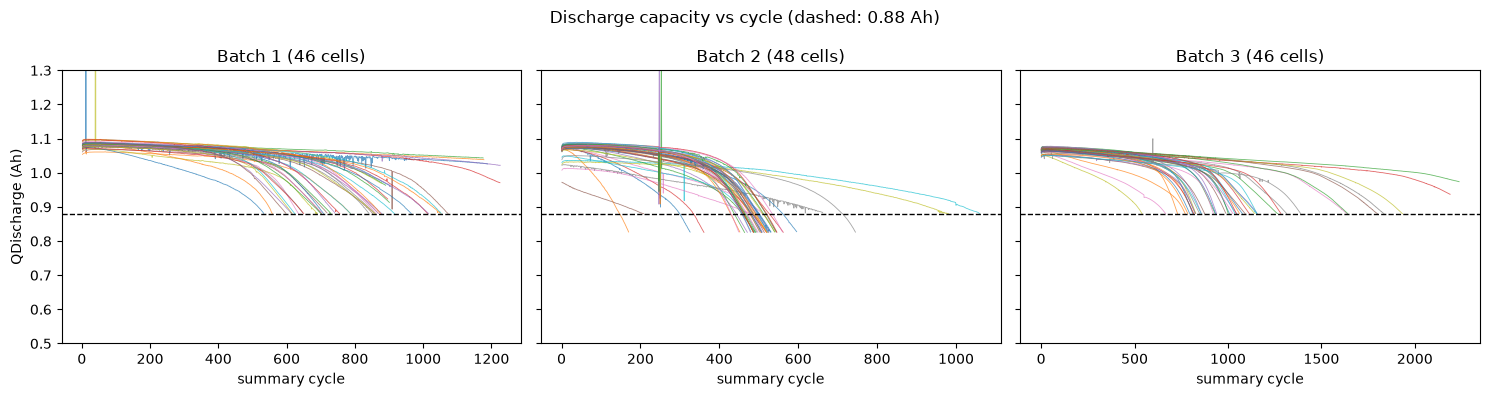

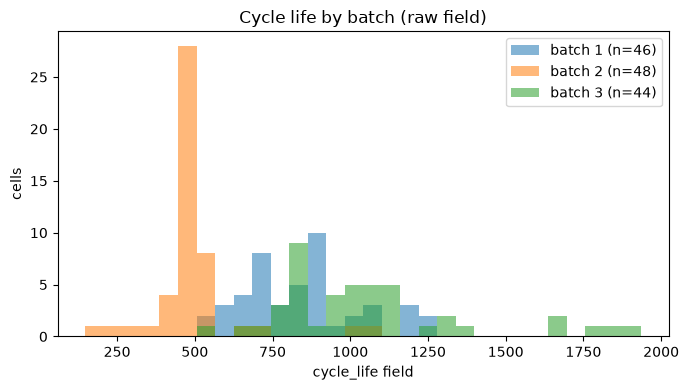

[ERROR] figure c ('b1c0', 0): ValueError: Qdlin length 2 != Vdlin length 1000


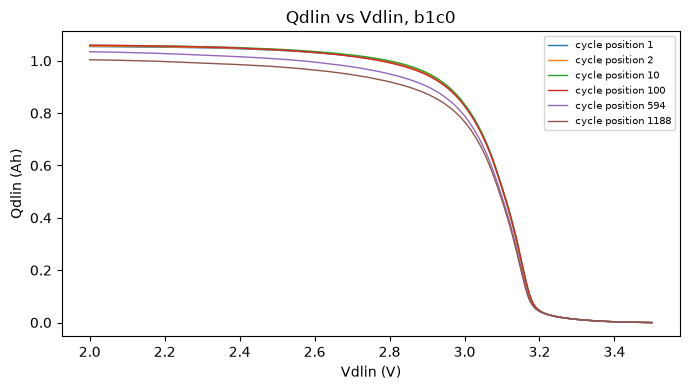

figures: ['fig_cycle_life_hist.png', 'fig_qd_vs_cycle.png', 'fig_qdlin_vs_vdlin.png']


In [11]:
section("8 Figures")


def fig_qd_vs_cycle():
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
    for ax, b in zip(axes, (1, 2, 3)):
        for cid in df.loc[df["batch"] == b, "cell_id"]:
            c = SUMMARY_CACHE.get(cid)
            if c is None or c["qd"].size == 0:
                continue
            qd = np.where(c["qd"] > 0, c["qd"], np.nan)       # zero entries are not plotted
            x = c["cycle"] if c["cycle"].size == qd.size else np.arange(qd.size)
            ax.plot(x, qd, lw=0.6, alpha=0.7)
        ax.axhline(EOL_AH, ls="--", lw=1.0, color="k")
        ax.set_ylim(0.5, 1.3)
        ax.set_title(f"Batch {b} ({int((df['batch'] == b).sum())} cells)")
        ax.set_xlabel("summary cycle")
    axes[0].set_ylabel("QDischarge (Ah)")
    fig.suptitle(f"Discharge capacity vs cycle (dashed: {EOL_AH:.2f} Ah)")
    fig.tight_layout()
    fig.savefig(FIG / "fig_qd_vs_cycle.png", dpi=150, bbox_inches="tight")
    plt.show()


def fig_cycle_life_hist():
    vals = df["cycle_life_field"].dropna()
    fig, ax = plt.subplots(figsize=(7, 4))
    if len(vals):
        bins = np.linspace(vals.min(), vals.max() + 1e-9, 31)
        for b in (1, 2, 3):
            v = df.loc[df["batch"] == b, "cycle_life_field"].dropna()
            if len(v):
                ax.hist(v, bins=bins, alpha=0.55, label=f"batch {b} (n={len(v)})")
        ax.legend()
    ax.set_xlabel("cycle_life field")
    ax.set_ylabel("cells")
    ax.set_title("Cycle life by batch (raw field)")
    fig.tight_layout()
    fig.savefig(FIG / "fig_cycle_life_hist.png", dpi=150, bbox_inches="tight")
    plt.show()


def fig_qdlin_vs_vdlin():
    b = 1
    i = first_kept_idx(b)
    cid = f"b{b}c{i}"
    v = VDLIN.get(b)
    keys = sorted(k for k in PEEK_QDLIN if k[0] == cid)
    if v is None or not keys:
        check("figure c inputs available", False, f"Vdlin={'ok' if v is not None else 'missing'}, Qdlin curves={len(keys)}", level="WARN")
        return
    fig, ax = plt.subplots(figsize=(7, 4))
    shown = 0
    for k in keys:
        q = PEEK_QDLIN[k]
        if q.size != v.size:
            record_error(f"figure c {k}", ValueError(f"Qdlin length {q.size} != Vdlin length {v.size}"))
            continue
        ax.plot(v, q, lw=1.0, label=f"cycle position {k[1]}")
        shown += 1
    if shown and PEEK_QDLIN[keys[0]].size == v.size:
        ax.scatter(v[::50], PEEK_QDLIN[keys[0]][::50], s=6, color="k", zorder=3, label="grid points (every 50th)")
    ax.set_xlabel("Vdlin (V)")
    ax.set_ylabel("Qdlin (Ah)")
    ax.set_title(f"Qdlin vs Vdlin, {cid}")
    ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(FIG / "fig_qdlin_vs_vdlin.png", dpi=150, bbox_inches="tight")
    plt.show()


for fn in (fig_qd_vs_cycle, fig_cycle_life_hist, fig_qdlin_vs_vdlin):
    try:
        fn()
    except Exception as e:
        record_error(fn.__name__, e)
        plt.close("all")
print("figures:", sorted(p.name for p in FIG.glob("*.png")))

## 9. Save artifacts
JSON reports and the inventory CSV.

In [12]:
section("9 Save artifacts")
smoke_clean = to_py(SMOKE)
ENV_REPORT = {
    "python": {"version": ENV["python_version"], "executable": ENV["python_executable"]},
    "environment": ENV, "packages": ENV["packages"], "gpu": GPU, "nvidia_smi": NVSMI,
    "gpu_verdict": GPU_VERDICT, "smoke_tests": smoke_clean,
}
dump_json(ENV_REPORT, OUT / "environment_report.json")
dump_json({"raw_dir": str(RAW), "files": FILES_INFO, "batch_map": {fi["file"]: fi["batch"] for fi in FILES_INFO},
           "extra_entries": extras, "sha256_computed": COMPUTE_SHA256}, OUT / "dataset_files.json")
dump_json(HDF5_STRUCTURE, OUT / "hdf5_structure.json")
dump_json(POLICY, OUT / "policy_overlap_preview.json")
df.to_csv(OUT / "raw_cell_inventory_phase1.csv", index=False)
print("written:", sorted(p.name for p in OUT.iterdir() if p.is_file()))

written: ['dataset_files.json', 'environment_report.json', 'hdf5_structure.json', 'policy_overlap_preview.json', 'raw_cell_inventory_phase1.csv', 'requirements_lock.txt']


In [13]:
section("9 Final report")


def fmt(v, nd=5):
    if v is None:
        return "NA"
    if isinstance(v, (float, np.floating)):
        return "NaN" if math.isnan(v) else f"{v:.{nd}g}"
    return str(v)


def build_report():
    W = 78
    L = []

    def head(t):
        L.extend(["", "-" * W, t, "-" * W])

    L.append("=" * W)
    L.append("PHASE 1 REPORT")
    L.append("=" * W)
    L.append(f"generated {datetime.now():%Y-%m-%d %H:%M:%S} | project {ROOT}")

    head("(1) ENVIRONMENT")
    for k in ("python_version", "python_executable", "os", "machine", "cpu_count", "ram_total_gb", "ram_available_gb", "disk_free_gb"):
        L.append(f"{k:18s} {ENV[k]}")
    L.append("packages           " + ", ".join(f"{p} {v}" for p, v in ENV["packages"].items()))
    L.append(f"torchvision/torchaudio installed: {pkg_version('torchvision')} / {pkg_version('torchaudio')}")

    head("(2) GPU")
    L.append(GPU_VERDICT)
    L.append("nvidia-smi: " + (A(NVSMI["gpus"]) if NVSMI["ok"] else "unavailable (" + A(NVSMI["error"]) + ")"))
    for k in ("torch_version", "torch_cuda_version", "cuda_available", "cudnn_version", "device_name", "capability", "total_vram_gb", "arch_list", "bf16_supported"):
        if k in GPU:
            L.append(f"{k:18s} {A(GPU[k])}")
    s = SMOKE
    L.append(f"M1 trainable params: {s['params']['count']} (expected 2977); " +
             ", ".join(f"{n} {c}" for n, _, c in s["params"]["breakdown"]))
    if "skipped" in s:
        L.append(s["skipped"])
    else:
        if "matmul" in s:
            L.append(f"fp32 matmul 4096^2: {s['matmul']['ms']:.2f} ms ({s['matmul']['tflops']:.2f} TFLOPS)")
        if "parity_max_abs_diff" in s:
            L.append(f"CPU vs GPU forward max abs diff: {s['parity_max_abs_diff']:.3e}")
        for mode in ("fp32", "bf16"):
            t = s.get(f"train_{mode}")
            if t:
                L.append(f"train {mode}: loss {t['first_loss']:.4f} -> {t['last_loss']:.4f} (last-10 mean {t['last10_mean_loss']:.4f}), "
                         f"{t['ms_per_step']:.2f} ms/step, peak mem {fmt(t['peak_mem_mb'], 4)} MB")
        if "repeatability" in s:
            L.append(f"same-seed repeatability: max param diff {s['repeatability']['max_param_diff']:.3e}, "
                     f"max loss diff {s['repeatability']['max_loss_diff']:.3e}")

    head("(3) DATASET FILES")
    for fi in FILES_INFO:
        L.append(f"batch {fi['batch']} | {fi['file']} | {fi['size_gb']} GB | {fi['modified']} | header {fi['header_ok']} | hdf5 {fi['is_hdf5']}")
        L.append(f"   sha256 {fi['sha256']}")

    head("(4) STRUCTURE")
    for b, info in sorted(STRUCT.items()):
        L.append(f"batch {b}: top-level {info['top_level_keys']} | cells {info['n_cells']}")
        L.append("  batch fields: " + ", ".join(f"{k}{d.get('shape')}:{d.get('dtype')}" for k, d in info["batch_fields"].items()))
        L.append("  summary keys: " + ", ".join(f"{k}{d.get('shape')}" for k, d in info["first_cell_summary"].items()))
        L.append("  cycles keys : " + ", ".join(f"{k}{d.get('shape')}" for k, d in info["first_cell_cycles"].items()))
        v = info["vdlin"]
        if v.get("location"):
            L.append(f"  Vdlin: {v['location']}")
            L.append(f"         len {v['length']}, min {fmt(v['min'])}, max {fmt(v['max'])}, first {fmt(v['first'])}, last {fmt(v['last'])}, "
                     f"strictly monotonic {v['strictly_monotonic']} ({v['direction']}), mean spacing {fmt(v['mean_spacing'])}")
        else:
            L.append("  Vdlin: NOT FOUND")
    for k, v in VDLIN_COMPARE.items():
        L.append(f"  Vdlin {k}: " + (f"same_length={v['same_length']}, max abs diff={fmt(v['max_abs_diff'])}" if v["comparable"] else "not comparable"))
    der = [c["derived"] for e in PEEK.values() for c in e["cycles"].values()]
    L.append(f"  Qdlin length per cycle: {sorted({d['qdlin_len'] for d in der if 'qdlin_len' in d})}")
    r1 = [d["qdlin_first_over_summary_qd"] for d in der if "qdlin_first_over_summary_qd" in d and not math.isnan(d["qdlin_first_over_summary_qd"])]
    r2 = [d["qdlin_last_over_summary_qd"] for d in der if "qdlin_last_over_summary_qd" in d and not math.isnan(d["qdlin_last_over_summary_qd"])]
    if r1 and r2:
        L.append(f"  Qdlin first / summary QD: {fmt(min(r1))} .. {fmt(max(r1))};  Qdlin last / summary QD: {fmt(min(r2))} .. {fmt(max(r2))}")
    vmin = [d["discharge_v_min"] for d in der if "discharge_v_min" in d]
    vmax = [d["discharge_v_max"] for d in der if "discharge_v_max" in d]
    imed = [d["discharge_i_median"] for d in der if "discharge_i_median" in d]
    dtm = [d["dt_median"] for d in der if "dt_median" in d]
    if vmin and imed:
        L.append(f"  discharge phase (I < -0.5 A): V {fmt(min(vmin))}..{fmt(max(vmax))}, median I {fmt(min(imed))}..{fmt(max(imed))} A; "
                 f"median dt {fmt(min(dtm))}..{fmt(max(dtm))} (units as stored)")

    head("(5) PER-BATCH CELL AND CYCLE STATISTICS")
    L.append(batch_summary(df).to_string(float_format=lambda v: f"{v:.4g}"))
    L.append(f"kept (124 set): {kept_counts} | flags: " + str(df["loader_flag"].replace("", "kept").value_counts().to_dict()))
    L.append(f"policies on kept cells: {POLICY['n_unique_policies']} unique (paper 72), {POLICY['n_policies_shared_by_more_than_one_cell']} shared, largest group {POLICY['largest_group_size']}")
    L.append(f"positional preview {POLICY['positional_preview_counts']}; primary-test policy in train: {POLICY['primary_test_cells_with_policy_in_train']['count']}/{POLICY['primary_test_cells_with_policy_in_train']['of']}; "
             f"secondary-test policy in train/primary: {POLICY['secondary_test_cells_with_policy_in_train_or_primary']['count']}/{POLICY['secondary_test_cells_with_policy_in_train_or_primary']['of']}")
    d3 = POLICY["development_vs_batch3"]
    L.append(f"development vs batch 3: {d3['batch3_cells_sharing_policy_with_development']}/{d3['batch3_cells']} batch-3 cells share a policy; {d3['policies_in_common']} common policies")
    if len(df_pairs):
        L.append("continuation pairs:")
        L.append(df_pairs.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

    head("(6) CHECKS")
    cnt = Counter(c["status"] for c in CHECKS)
    L.append(f"PASS {cnt.get('PASS', 0)} | WARN {cnt.get('WARN', 0)} | FAIL {cnt.get('FAIL', 0)}")
    for st in ("FAIL", "WARN"):
        items = [c for c in CHECKS if c["status"] == st]
        L.append(f"{st} ({len(items)}):")
        L.extend(f"  - [{c['section'][:2].strip()}] {c['name']} | {c['detail']}" for c in items) if items else L.append("  none")
    ps = [c for c in CHECKS if c["status"] == "PASS"]
    L.append(f"PASS ({len(ps)}):")
    L.extend(f"  - {c['name']}" for c in ps)

    head("(7) RECORDED ERRORS AND ANOMALIES")
    L.append(f"errors ({len(ERRORS)}):")
    L.extend(f"  - {e}" for e in ERRORS) if ERRORS else L.append("  none")
    L.append(f"anomalies ({len(ANOMALIES)}):")
    L.extend(f"  - {a}" for a in ANOMALIES) if ANOMALIES else L.append("  none")

    head("(8) ARTIFACT FILES")
    for p in sorted(OUT.rglob("*")):
        if p.is_file():
            rel = p.relative_to(OUT).as_posix()
            L.append(f"  {rel:42s} " + ("(this file)" if rel == "phase1_report.txt" else f"{p.stat().st_size:>12,d} bytes"))

    head("(9) RUNTIME")
    section("done")
    L.append(f"total runtime: {time.time() - T0:.1f} s")
    L.append("by section: " + ", ".join(f"{k.split(' ')[0]}={v:.1f}s" for k, v in SECTION_TIMES.items() if v >= 0.05))
    return A("\n".join(L))


try:
    REPORT = build_report()
except Exception as e:
    record_error("build_report", e)
    REPORT = "PHASE 1 REPORT\nreport generation failed: " + A(e) + "\nerrors: " + "; ".join(ERRORS)
(OUT / "phase1_report.txt").write_text(REPORT + "\n", encoding="ascii", errors="replace")
print(REPORT)

for _f in H.values():
    try:
        _f.close()
    except Exception as e:
        print("close failed:", A(e))

PHASE 1 REPORT
generated 2026-11-01 14:26:39 | project c:\workstation\3RD YEAR\Battery-Health-Estimation

------------------------------------------------------------------------------
(1) ENVIRONMENT
------------------------------------------------------------------------------
python_version     3.13.13
python_executable  c:\workstation\3RD YEAR\Battery-Health-Estimation\.venv\Scripts\python.exe
os                 Windows-11-10.0.26300-SP0
machine            AMD64
cpu_count          12
ram_total_gb       15.71
ram_available_gb   0.49
disk_free_gb       38.5
packages           torch 2.14.1+cu130, numpy 2.5.4, pandas 3.1.0, scipy 1.18.1, h5py 3.16.0, scikit-learn 1.9.1, matplotlib 3.11.2, pyarrow 26.0.0, psutil 7.2.2, tqdm 4.70.1
torchvision/torchaudio installed: None / None

------------------------------------------------------------------------------
(2) GPU
------------------------------------------------------------------------------
GPU VERDICT: READY - NVIDIA GeForce RTX 3050 6G